#### Defining the physical setup the code is emulating

A camera is positioned so that it can capture the motion of a wave (soltion) in a wave-flume. 
The camera has a limited field of view: L, and a fixed number of pixels in the frame: N. 

For periodic waves we require that a whole number of waves can pass in L, this is so that the FFT makes sense, a period is captured. 
Looking at solitons this can be done with zero-padding, forcing the wave to get the dimensions needed for periodization. 

In [1]:
import sys
from pathlib import Path

root = Path.cwd().parent.parent
sys.path.insert(0,str(root))

from camera.camera_file import Camera
from camera.spectralCamera import *
from camera.pdeCamera import *

import numpy as np
import matplotlib.pyplot as plt

In [2]:
c1  = Camera(L = 4*np.pi , N=2**7, dt=1e-3)

In [3]:
k1 = KdVNewton(P=c1.L, target_amp=0.25,mean=0, camera=c1)
k1.solve_w_continuation()
k2 = KdVNewton(P=c1.L/2, target_amp=0.25,mean=0, camera=c1)
k2.solve_w_continuation()

w1 = WhithamNewton(P=c1.L, target_amp=0.25,mean=0, camera=c1)
w1.solve_w_continuation()
w2 = WhithamNewton(P=c1.L/2, target_amp=0.25,mean=0, camera=c1)
w2.solve_w_continuation()


amplitude = 0.17674591335628248
Crest amplitude = 0.25
Wave speed c = 0.9975554800903321
Constant B = 0.00647118954970576


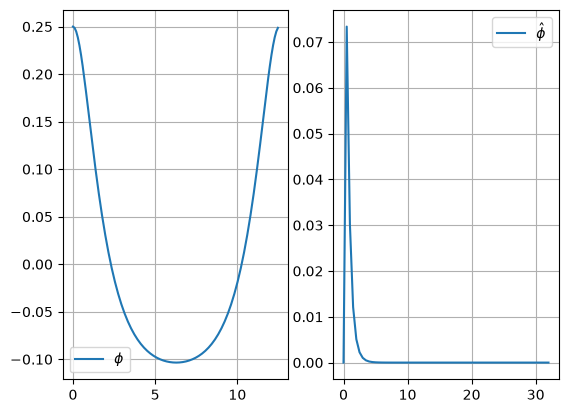

amplitude = 0.1970088331646119
Crest amplitude = 0.25
Wave speed c = 0.8982707022091062
Constant B = 0.008705512983701112


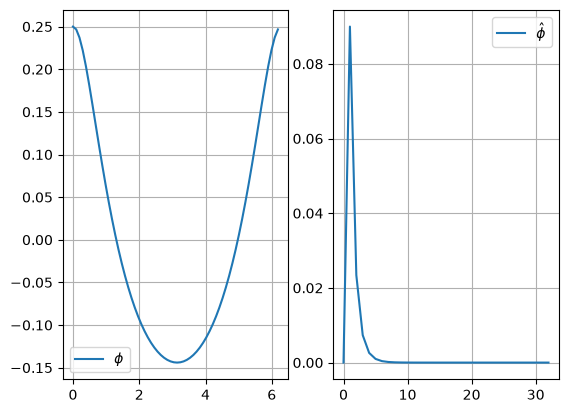

In [4]:
w1._plot_()
w2._plot_()

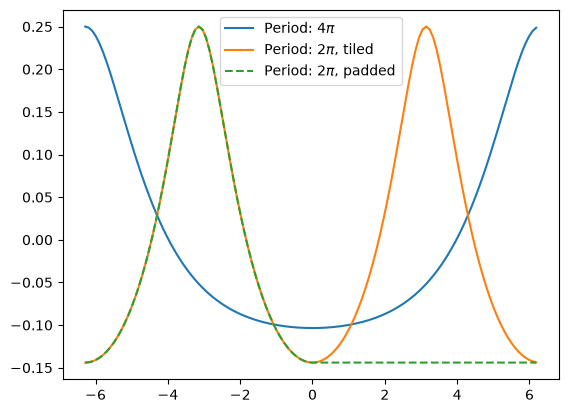

In [5]:
plt.plot(c1.x, w1.get_physical(w1.phi_hat), label = r"Period: $4\pi$");

phi2 = w2.get_physical(w2.phi_hat)
phi2 = np.roll(phi2, int(w2.N//2))
#And for the wave of half period one can tile it, (copy)
tiled = np.tile(phi2, int(c1.L//w2.P))
plt.plot(c1.x, tiled, label = r"Period: $2\pi$, tiled");
#Or one can zero-pad it
padded = np.zeros(c1.N) - np.abs(np.min(phi2))
padded[:w2.N] = phi2
plt.plot(c1.x, padded, label = r"Period: $2\pi$, padded", linestyle ='--');
plt.legend()
plt.show()



In [6]:
#Tiling and padding are however not equivalent, let us solve them in time:
T=5
sTile = KdV(camera=c1, T=T, u0=tiled)
t,tiled_sol = sTile.splitStep()

# animate_solution_nb(c1.x,tiled_sol)

In [7]:
sTile.conservation()
# A = tiled_sol.max(axis=1) - tiled_sol.min(axis = 1)
# plt.plot(A)

----- Conservation of  Mass -----
Initial Mass: 9.54e-18
Final Mass: 2.05e-17
Maximum error: 7.77e-17
Relative error: 8.14e+00
------------------------------
----- Conservation of  L2 -----
Initial L2: 2.19e-01
Final L2: 2.19e-01
Maximum error: 5.27e-15
Relative error: 2.41e-14
------------------------------
----- Conservation of  Hamiltonian -----
Initial Hamiltonian: 8.94e-02
Final Hamiltonian: 8.94e-02
Maximum error: 5.13e-10
Relative error: 5.73e-09
------------------------------


In [8]:
sPad = KdV(camera=c1, T=T, u0=padded)
t,padded_sol = sPad.splitStep()

animate_solution_nb(c1.x,tiled_sol -padded_sol)

Dette kan sees på teoretisk 

In [9]:
sPad.conservation()
# A = padded_sol.max(axis=1) - padded_sol.min(axis = 1)
# plt.plot(A)

----- Conservation of  Mass -----
Initial Mass: -9.05e-01
Final Mass: -9.05e-01
Maximum error: 2.22e-16
Relative error: 2.45e-16
------------------------------
----- Conservation of  L2 -----
Initial L2: 2.40e-01
Final L2: 2.40e-01
Maximum error: 5.66e-14
Relative error: 2.36e-13
------------------------------
----- Conservation of  Hamiltonian -----
Initial Hamiltonian: 1.07e-01
Final Hamiltonian: 1.07e-01
Maximum error: 2.04e-10
Relative error: 1.92e-09
------------------------------


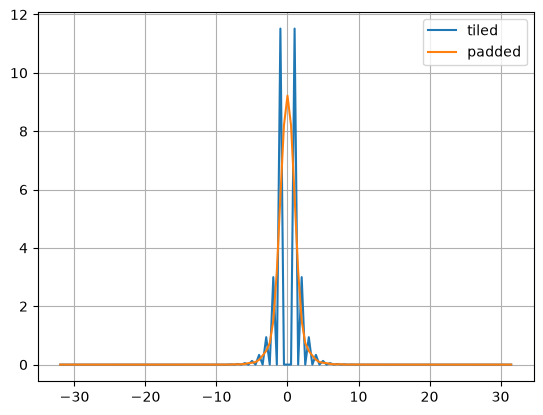

In [10]:
i = 0
order = np.argsort(c1.k)
plt.plot(c1.k[order], np.abs(nf.fft(tiled_sol[i]))[order], label = "tiled")
plt.plot(c1.k[order], np.abs(nf.fft(padded_sol[i]))[order], label = "padded")
plt.grid()
plt.legend()
plt.show()


In [11]:
Ft = np.fft.rfft(tiled); Fp = np.fft.rfft(padded)
print(np.allclose(np.abs(Fp[2::2]), np.abs(Ft[2::2])/2))   # True (k=0 excluded)
print(np.abs(Ft[1::2]).max(), np.abs(Fp[1::2]).max())      # the odd k's in the padded one, leads to radiation

True
0.0 8.19885267908387
